# Каскадные нейросети для детекции повреждений бетона мостов — этап 1

Данные CODEBRIM и базовая модель YOLOv8.

**Задача:** найти на фотографии повреждения бетона и определить их тип: трещина, скол, высолы, оголённая арматура, ржавые подтёки. Разметка многометочная: у одной рамки может быть несколько классов.

**Датасет:** [CODEBRIM](https://zenodo.org/records/2620293) (Mundt et al., CVPR 2019): 1590 фото 30 мостов, до 6000×4000 пикселей.

**Конвейер:**
1. Скачивание архива (8,3 ГБ) с проверкой MD5, разбор XML-разметки.
2. Уменьшение фото до 1600 px с пересчётом рамок и исправлением EXIF-ориентации; компактная копия сохраняется на Google Диск.
3. Статистика датасета: дисбаланс классов, многометочность, совместная встречаемость, размеры объектов.
4. Стратифицированное разбиение **по фотографиям** 70/15/15 (без утечки рамок одного фото между выборками).
5. Конвертация в формат YOLO.
6. Дообучение YOLOv8n (предобучен на COCO), оценка на test, анализ ошибок.
7. Три запуска с разными seed → среднее ± std.

**Результат (test, 3 запуска):** mAP@0.5 = 0.326 ± 0.011, F1 = 0.400 ± 0.011. Подробности — в конце ноутбука и в README.

Запускалось в Google Colab (GPU T4). Первый запуск с подготовкой данных ~1 час, следующие начинаются с готовой копии на Диске.


## Шаг 1. Проверяем GPU

Должна появиться таблица с **Tesla T4**.

In [1]:
!nvidia-smi

Fri Oct 30 13:58:07 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Шаг 2. Подключаем Google Диск и создаём папки

- `codebrim_compact/` — уменьшенные фото и таблица разметки (создаётся один раз в шаге 8);
- `figures/` — рисунки для текста;
- `results/` — таблицы с метриками;
- `runs/` — обученные модели и графики обучения;
- `split.csv` — разбиение на train/val/test, одно для всех экспериментов.


In [2]:
import os
from pathlib import Path

try:
    from google.colab import drive          # модуль есть только на серверах Colab
    drive.mount('/content/drive')
    IN_COLAB = True
    BASE_DIR = Path('/content/drive/MyDrive/VKR_codebrim')   # результаты  Google Диск
    WORK_DIR = Path('/content')                               # временные данные  диск сервера Colab
except ImportError:
    IN_COLAB = False                        # запуск на своём компьютере
    BASE_DIR = Path('VKR_codebrim').resolve()
    WORK_DIR = Path('work').resolve()

COMPACT_DIR = BASE_DIR / 'codebrim_compact'   # уменьшенная копия датасета на Диске
RAW_DIR     = WORK_DIR / 'codebrim_raw'       # распакованные оригиналы (только на время подготовки)
DATA_DIR    = WORK_DIR / 'datasets' / 'codebrim_yolo'   # датасет в формате YOLO
FIG_DIR, RES_DIR, RUNS_DIR = BASE_DIR / 'figures', BASE_DIR / 'results', BASE_DIR / 'runs'
for d in (FIG_DIR, RES_DIR, RUNS_DIR, WORK_DIR):
    d.mkdir(parents=True, exist_ok=True)

HAVE_COMPACT = (COMPACT_DIR / 'annotations.csv').exists()
print('Colab:', IN_COLAB)
print('Результаты сохраняются в:', BASE_DIR)
print('Компактная копия датасета уже есть:', HAVE_COMPACT,
      '-> шаги 5–8 будут пропущены' if HAVE_COMPACT else '-> шаги 5–8 подготовят её (~1 час, один раз)')

Mounted at /content/drive
Colab: True
Результаты сохраняются в: /content/drive/MyDrive/VKR_codebrim
Компактная копия датасета уже есть: True -> шаги 5–8 будут пропущены


## Шаг 3. Устанавливаем библиотеку YOLO

**ultralytics** — библиотека с моделями YOLO. Устанавливается при каждом новом подключении к Colab.

In [3]:
!pip install -q ultralytics

## Шаг 4. Настройки эксперимента

| Параметр | Что это | Значение |
|---|---|---|
| `MODEL_NAME` | модель YOLO: `n` — самая маленькая и быстрая, `s` — побольше и точнее | `yolov8n.pt` |
| `EPOCHS` | сколько раз модель проходит всю обучающую выборку | 100 |
| `IMG_SIZE` | размер, до которого масштабируется фото при обучении | 640 |
| `BATCH` | сколько фото обрабатывается за один шаг обучения | 16 |
| `SEED` | seed запуска; запуски с разными seed усредняем | 0, потом 1, 2 |
| `SPLIT_SEED` | seed разбиения на выборки. **Не менять** | 42 |
| `MAX_SIDE` | до какой длинной стороны уменьшать оригиналы при подготовке (делается один раз). **Не менять после подготовки** | 1600 |
| `QUICK_TEST` | `True` — пробный прогон на 3 эпохи для проверки конвейера | `False` |

Про `IMG_SIZE`: трещины тонкие, и при 640 часть из них может «потеряться». Сравнение 640 и 1024 — хороший отдельный эксперимент на потом (подбор гиперпараметров). Поэтому фото сохраняются с запасом, до 1600 пикселей.

In [6]:
MODEL_NAME = 'yolov8n.pt'
EPOCHS     = 100
IMG_SIZE   = 640
BATCH      = 16
SEED       = 0              # запуски: 0, 1, 2
SPLIT_SEED = 42             # НЕ менять
MAX_SIDE   = 1600           # НЕ менять после подготовки данных
QUICK_TEST = True          # True — быстрая проверка конвейера на 3 эпохах

if QUICK_TEST:
    EPOCHS = 3

RUN_NAME = f"{Path(MODEL_NAME).stem}_img{IMG_SIZE}_seed{SEED}" + ("_quick2" if QUICK_TEST else "")
print('Имя запуска:', RUN_NAME, '| эпох:', EPOCHS)

Имя запуска: yolov8n_img640_seed0_quick2 | эпох: 3


## Шаг 5. Скачиваем и распаковываем архив (только при первом запуске)

Архив `CODEBRIM_original_images.zip` (8,3 ГБ) скачивается с Zenodo на диск сервера Colab (5–15 минут).

Затем проверяется контрольная сумма MD5 (что файл скачался целиком и без повреждений) и архив распаковывается программой 7-Zip (обычные zipfile и unzip этот архив не открывают).

Лицензия CODEBRIM допускает только некоммерческое и учебное использование, поэтому данные в репозиторий не входят.

Если компактная копия уже есть на Диске, ячейка ничего не делает.

In [7]:
import hashlib, shutil

ZIP_URL = 'https://zenodo.org/records/2620293/files/CODEBRIM_original_images.zip?download=1'
ZIP_MD5 = '27baf3a036d0b7d757ff4df47c08c449'      # контрольная сумма со страницы Zenodo
ZIP_PATH = WORK_DIR / 'CODEBRIM_original_images.zip'

def md5_of(path, chunk=2**24):
    h = hashlib.md5()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(chunk), b''):
            h.update(block)
    return h.hexdigest()

if HAVE_COMPACT:
    print('Компактная копия есть на Диске: скачивание не нужно.')
else:
    if not ZIP_PATH.exists():
        print('Скачиваем 8,3 ГБ... (полоса прогресса ниже)')
        !wget -q --show-progress -O "{ZIP_PATH}" "{ZIP_URL}"
    print('Проверяем MD5 (1–2 минуты)...')
    got = md5_of(ZIP_PATH)
    if got != ZIP_MD5:
        ZIP_PATH.unlink()
        raise RuntimeError(f'Архив повреждён (MD5 {got}). Файл удалён — запустите ячейку ещё раз.')
    print('MD5 совпадает, архив целый.')
    n_files = sum(1 for _ in RAW_DIR.rglob('*') if _.is_file()) if RAW_DIR.exists() else 0
    if n_files < 1000:                                  # нет папки или распаковка была прервана
        shutil.rmtree(RAW_DIR, ignore_errors=True)
        print('Распаковываем (5–10 минут)...')
        # Архив больше 4 ГБ упакован без ZIP64: смещения файлов внутри "перескакивают" границу 4 ГБ.
        # zipfile Python (BadZipFile) и unzip ("possible zip bomb") такой архив не открывают, а 7-Zip справляется.
        !apt-get -qq install -y p7zip-full > /dev/null
        !7z x "{ZIP_PATH}" -o"{RAW_DIR}" -y > /dev/null
        n_files = sum(1 for _ in RAW_DIR.rglob('*') if _.is_file())
    print('Готово:', RAW_DIR, '| файлов:', n_files)

Компактная копия есть на Диске: скачивание не нужно.


## Шаг 6. Смотрим, что внутри архива

Печатаем дерево папок, считаем файлы и выводим пример XML-разметки, чтобы проверить её формат перед разбором.

In [8]:
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}

def show_tree(root, max_depth=3, max_files=3):
    root = Path(root)
    for dirpath, dirnames, filenames in os.walk(root):
        depth = len(Path(dirpath).relative_to(root).parts)
        if depth > max_depth:
            continue
        indent = '    ' * depth
        print(f"{indent}{Path(dirpath).name}/  ({len(filenames)} файлов)")
        for f in sorted(filenames)[:max_files]:
            print(f"{indent}    {f}")

if HAVE_COMPACT:
    print('Пропускаем: данные уже подготовлены.')
else:
    show_tree(RAW_DIR)
    all_images = [p for p in RAW_DIR.rglob('*') if p.suffix.lower() in IMG_EXT and not p.name.startswith('._')]
    all_xml = [p for p in RAW_DIR.rglob('*.xml') if not p.name.startswith('._')]
    print('\nИзображений:', len(all_images), '| XML-файлов:', len(all_xml))
    if all_xml:
        sample_xml = sorted(all_xml)[0]
        print(f'\n===== Пример разметки: {sample_xml.name} =====')
        print(sample_xml.read_text(errors='replace')[:3000])

Пропускаем: данные уже подготовлены.


## Шаг 7. Читаем разметку

Каждый объект в XML — это рамка (`bndbox`: углы `xmin, ymin, xmax, ymax` в пикселях) и её классы. В CODEBRIM у одной рамки может быть несколько классов: например, оголённая арматура **и** ржавые подтёки **и** скол. Это называется **многометочная (multi-label)** разметка.

Функция `labels_of` понимает оба способа записи классов:
- тегами-флажками внутри объекта: `<Crack>1</Crack><Spallation>0</Spallation>...`;
- через имя объекта: `<name>Crack</name>`.

Рамки класса **background** (фон) — это специально размеченные участки без дефектов. Детектору они не нужны, но пригодятся на этапе 2 для обучения классификатора «дефект / не дефект».

Итог — таблица `ann`: одна строка на рамку, у каждой — список классов.

In [9]:
import re
import xml.etree.ElementTree as ET
import pandas as pd

DEFECTS = ['crack', 'spallation', 'efflorescence', 'exposed_bars', 'corrosion_stain']   # 5 классов детектора
CLASS_KEYS = {'crack': 'crack', 'spallation': 'spallation', 'efflorescence': 'efflorescence',
              'exposedbars': 'exposed_bars', 'exposedbar': 'exposed_bars',
              'corrosionstain': 'corrosion_stain', 'corrosion': 'corrosion_stain',
              'background': 'background'}
norm = lambda s: re.sub(r'[^a-z]', '', (s or '').lower())     # 'Exposed Bars' -> 'exposedbars'

def labels_of(obj):
    # классы одной рамки: теги-флажки со значением 1 и/или имя объекта
    labels = set()
    for el in obj.iter():
        key = norm(el.tag)
        if key in CLASS_KEYS and (el.text or '').strip() in ('1', '1.0', 'true', 'True'):
            labels.add(CLASS_KEYS[key])
    name = obj.find('name')
    if name is not None and norm(name.text) in CLASS_KEYS:
        labels.add(CLASS_KEYS[norm(name.text)])
    return labels

def box_of(obj):
    bb = obj.find('bndbox') if obj.find('bndbox') is not None else obj
    vals = [bb.find(k) for k in ('xmin', 'ymin', 'xmax', 'ymax')]
    if any(v is None for v in vals):
        return None
    return [float(v.text) for v in vals]

if HAVE_COMPACT:
    print('Пропускаем: разметка уже сохранена в', COMPACT_DIR / 'annotations.csv')
else:
    img_by_name = {p.name.lower(): p for p in all_images}
    img_by_stem = {p.stem.lower(): p for p in all_images}
    rows, no_image, skipped_xml = [], [], 0
    for xml_path in sorted(all_xml):
        root = ET.parse(xml_path).getroot()
        objects = root.findall('.//object')
        fname = root.findtext('filename')
        img_path = img_by_name.get(Path(fname).name.lower()) if fname else None
        img_path = img_path or img_by_stem.get(xml_path.stem.lower())
        if img_path is None:
            if objects:
                no_image.append(xml_path.name)
            else:
                skipped_xml += 1          # служебный XML без рамок и без своего изображения
            continue
        xml_w = root.findtext('size/width'); xml_h = root.findtext('size/height')
        base = dict(image=str(img_path), stem=img_path.stem,
                    xml_w=int(float(xml_w)) if xml_w else None, xml_h=int(float(xml_h)) if xml_h else None)
        if not objects:
            rows.append({**base, 'labels': '', 'xmin': None, 'ymin': None, 'xmax': None, 'ymax': None})
        for obj in objects:
            box = box_of(obj)
            if box is None:
                continue
            labs = labels_of(obj) or {'unknown'}
            rows.append({**base, 'labels': '|'.join(sorted(labs)),
                         'xmin': box[0], 'ymin': box[1], 'xmax': box[2], 'ymax': box[3]})

    # изображения, у которых вообще нет XML, — тоже фото без дефектов
    stems_with_xml = {r['stem'] for r in rows}
    for p in all_images:
        if p.stem not in stems_with_xml:
            rows.append(dict(image=str(p), stem=p.stem, xml_w=None, xml_h=None, labels='',
                             xmin=None, ymin=None, xmax=None, ymax=None))

    ann_raw = pd.DataFrame(rows)
    # одна и та же рамка, записанная несколькими объектами с разными классами -> одна рамка со списком классов
    has = ann_raw['labels'] != ''
    keys = ['image', 'stem', 'xml_w', 'xml_h', 'xmin', 'ymin', 'xmax', 'ymax']
    merged = (ann_raw[has].groupby(keys, dropna=False)['labels']
              .apply(lambda s: '|'.join(sorted(set('|'.join(s).split('|'))))).reset_index())
    ann_raw = pd.concat([merged, ann_raw[~has]], ignore_index=True)
    assert ann_raw['labels'].ne('').any(), 'Разметка не найдена: проверьте формат XML (шаг 6).'
    n_unknown = ann_raw['labels'].str.contains('unknown').sum()
    print('Изображений:', ann_raw['stem'].nunique(), '| рамок:', ann_raw['labels'].ne('').sum())
    if no_image:
        print(f'Внимание: {len(no_image)} XML без изображения, например {no_image[:3]}')
    if skipped_xml:
        print(f'Пропущено служебных XML без рамок: {skipped_xml}')
    if n_unknown:
        print(f'ВНИМАНИЕ: у {n_unknown} рамок класс не распознан (unknown) — проверьте имена тегов (шаг 6).')
    print(ann_raw['labels'].value_counts().head(15))

Пропускаем: разметка уже сохранена в /content/drive/MyDrive/VKR_codebrim/codebrim_compact/annotations.csv


## Шаг 8. Уменьшаем фото и сохраняем компактную копию на Диск (один раз)

Оригиналы огромные (до 6000×4000), а сеть всё равно работает с 640–1280 пикселями. Поэтому каждое фото уменьшается так, чтобы длинная сторона была `MAX_SIDE` = 1600, и сохраняется в JPEG. Координаты рамок пересчитываются в том же масштабе.

**Поворот фото.** Камеры записывают ориентацию снимка в служебное поле EXIF, и разные программы по-разному его учитывают. Чтобы рамки не «съехали», ориентация сверяется с размером из XML: если ширина и высота перепутаны, фото поворачивается по EXIF. Итоговые файлы сохраняются уже без EXIF, поэтому дальше все программы видят их одинаково.

Займёт ~15–25 минут. Результат: `VKR_codebrim/codebrim_compact/` на Диске (папка `images` и таблица `annotations.csv`). После этого распакованные оригиналы на сервере удаляются, чтобы освободить место.

In [10]:
import shutil
from PIL import Image, ImageOps
from tqdm.auto import tqdm

if HAVE_COMPACT:
    print('Пропускаем: компактная копия уже есть.')
else:
    (COMPACT_DIR / 'images').mkdir(parents=True, exist_ok=True)
    out_rows, rotated = [], 0
    for stem, g in tqdm(ann_raw.groupby('stem'), desc='Уменьшаем фото'):
        r0 = g.iloc[0]
        with Image.open(r0['image']) as im:
            w, h = im.size
            if pd.notna(r0['xml_w']) and (w, h) == (r0['xml_h'], r0['xml_w']) and w != h:
                im = ImageOps.exif_transpose(im)        # размеры перепутаны -> поворачиваем по EXIF
                w, h = im.size
                rotated += 1
            s = min(1.0, MAX_SIDE / max(w, h))
            nw, nh = round(w * s), round(h * s)
            im.convert('RGB').resize((nw, nh), Image.LANCZOS).save(COMPACT_DIR / 'images' / f'{stem}.jpg', quality=92)
        for r in g.itertuples():
            row = dict(stem=stem, width=nw, height=nh, labels=r.labels)
            if r.labels:
                x0, y0 = max(0, r.xmin) * s, max(0, r.ymin) * s
                x1, y1 = min(w, r.xmax) * s, min(h, r.ymax) * s
                if x1 - x0 < 2 or y1 - y0 < 2:        # вырожденная рамка
                    continue
                row.update(xmin=round(x0, 1), ymin=round(y0, 1), xmax=round(x1, 1), ymax=round(y1, 1))
            out_rows.append(row)
    pd.DataFrame(out_rows).to_csv(COMPACT_DIR / 'annotations.csv', index=False)
    HAVE_COMPACT = True
    print('Повёрнуто по EXIF:', rotated)
    print('Компактная копия сохранена:', COMPACT_DIR)
    if IN_COLAB:                                       # освобождаем место на сервере
        shutil.rmtree(RAW_DIR, ignore_errors=True)
        print('Распакованные оригиналы удалены (архив .zip оставлен до отключения сервера).')

ann = pd.read_csv(COMPACT_DIR / 'annotations.csv', keep_default_na=False)
ann['labels'] = ann['labels'].astype(str)
for c in ['xmin', 'ymin', 'xmax', 'ymax']:
    ann[c] = pd.to_numeric(ann[c], errors='coerce')
print('Загружено: изображений', ann['stem'].nunique(), '| рамок', (ann['labels'] != '').sum())

Пропускаем: компактная копия уже есть.
Загружено: изображений 1590 | рамок 5233


## Шаг 9. Статистика датасета

Считаем:
- сколько рамок и изображений у каждого класса — виден **дисбаланс** (высолов мало);
- сколько классов у одной рамки — насколько разметка **многометочная**;
- **матрицу совместной встречаемости**: какие повреждения появляются вместе (например, оголённая арматура почти всегда с ржавчиной);
- размеры рамок относительно фото — насколько мелкие объекты ищем;
- сколько фото **без дефектов** (на них проверяется число ложных срабатываний).

Всё сохраняется в `results/` и `figures/`.

Фото всего: 1590 | с дефектами: 1022 | без дефектов: 568
Рамок с дефектами: 5181 | рамок фона: 49
             класс  рамок  изображений  ср. площадь рамки, % фото
0            crack   2502          629                        4.1
1       spallation   1892          563                       10.5
2    efflorescence    828          320                        7.6
3     exposed_bars   1502          446                       10.8
4  corrosion_stain   1550          573                        9.6

Сколько классов у рамки:
n_labels
1    3201
2     981
3     899
4      86
5      14


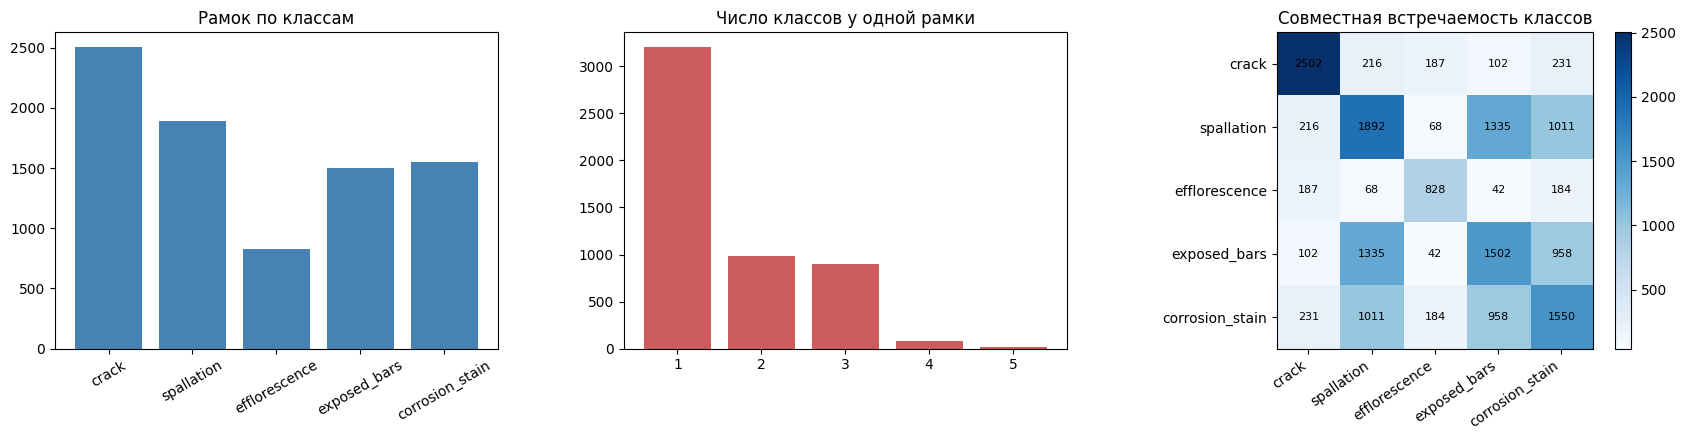

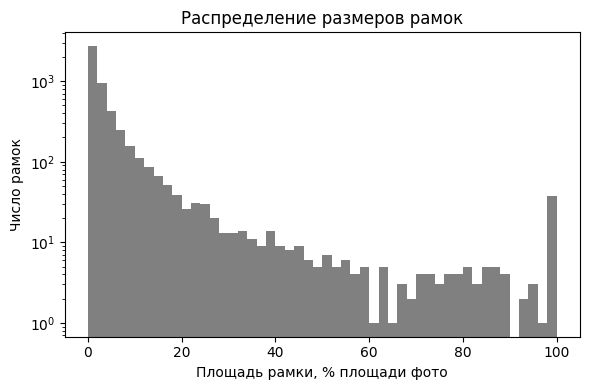

In [11]:
import numpy as np
import matplotlib.pyplot as plt

boxes = ann[ann['labels'] != ''].copy()
boxes['label_set'] = boxes['labels'].str.split('|')
for c in DEFECTS + ['background']:
    boxes[c] = boxes['label_set'].apply(lambda s, c=c: int(c in s))
defect_boxes = boxes[boxes[DEFECTS].sum(axis=1) > 0].copy()
bg_boxes = boxes[(boxes['background'] == 1) & (boxes[DEFECTS].sum(axis=1) == 0)]
defect_boxes['n_labels'] = defect_boxes[DEFECTS].sum(axis=1)
defect_boxes['area_rel'] = ((defect_boxes.xmax - defect_boxes.xmin) * (defect_boxes.ymax - defect_boxes.ymin)
                            / (defect_boxes.width * defect_boxes.height))

imgs_with_defects = set(defect_boxes['stem'])
n_img = ann['stem'].nunique()
print(f'Фото всего: {n_img} | с дефектами: {len(imgs_with_defects)} | без дефектов: {n_img - len(imgs_with_defects)}')
print(f'Рамок с дефектами: {len(defect_boxes)} | рамок фона: {len(bg_boxes)}')

stats = pd.DataFrame({
    'класс': DEFECTS,
    'рамок': [int(defect_boxes[c].sum()) for c in DEFECTS],
    'изображений': [defect_boxes.loc[defect_boxes[c] == 1, 'stem'].nunique() for c in DEFECTS],
    'ср. площадь рамки, % фото': [round(100 * defect_boxes.loc[defect_boxes[c] == 1, 'area_rel'].mean(), 1) for c in DEFECTS],
})
stats.to_csv(RES_DIR / 'dataset_stats.csv', index=False, encoding='utf-8-sig')
display(stats) if 'display' in globals() else print(stats)

card = defect_boxes['n_labels'].value_counts().sort_index()
print('\nСколько классов у рамки:'); print(card.to_string())
co = defect_boxes[DEFECTS].T.dot(defect_boxes[DEFECTS])      # матрица совместной встречаемости
co.to_csv(RES_DIR / 'cooccurrence.csv', encoding='utf-8-sig')

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].bar(stats['класс'], stats['рамок'], color='steelblue'); ax[0].set_title('Рамок по классам')
ax[0].tick_params(axis='x', rotation=30)
ax[1].bar(card.index.astype(str), card.values, color='indianred'); ax[1].set_title('Число классов у одной рамки')
im = ax[2].imshow(co.values, cmap='Blues'); ax[2].set_title('Совместная встречаемость классов')
ax[2].set_xticks(range(5)); ax[2].set_xticklabels(DEFECTS, rotation=35, ha='right')
ax[2].set_yticks(range(5)); ax[2].set_yticklabels(DEFECTS)
for i in range(5):
    for j in range(5):
        ax[2].text(j, i, int(co.values[i, j]), ha='center', va='center', fontsize=8)
plt.colorbar(im, ax=ax[2], fraction=0.046)
plt.tight_layout(); plt.savefig(FIG_DIR / 'dataset_statistics.png', dpi=200); plt.show()

plt.figure(figsize=(6, 4))
plt.hist(100 * defect_boxes['area_rel'], bins=50, color='gray')
plt.xlabel('Площадь рамки, % площади фото'); plt.ylabel('Число рамок'); plt.yscale('log')
plt.title('Распределение размеров рамок'); plt.tight_layout()
plt.savefig(FIG_DIR / 'box_sizes.png', dpi=200); plt.show()

## Шаг 10. Делим фото на train / val / test

- **train** (70 %) — обучение; **val** (15 %) — контроль во время обучения и подбор порогов; **test** (15 %) — итоговые цифры, модель не видит их до конца.
- Делим **по фотографиям**, а не по рамкам: все рамки одного фото попадают в одну выборку, иначе модель «подсмотрит» тест.
- **Стратификация:** каждому фото присваивается его самый редкий класс (высолы реже всего), фото без дефектов — класс `none`. Так редкие классы и пустые фото равномерно попадут во все выборки.
- Разбиение сохраняется в `split.csv` на Диске и используется во всех экспериментах.

Ограничение: фото одного моста могут попасть и в train, и в test, потому что номер моста в разметке не указан. Это может немного завышать результаты, причём одинаково для всех моделей, так что сравнение остаётся честным.

In [12]:
from sklearn.model_selection import train_test_split

split_path = BASE_DIR / 'split.csv'
if split_path.exists():
    split_df = pd.read_csv(split_path)
    print('Используем сохранённое разбиение:', split_path)
else:
    freq = {c: defect_boxes[c].sum() for c in DEFECTS}
    def rarest(stem):
        present = [c for c in DEFECTS if defect_boxes.loc[defect_boxes['stem'] == stem, c].any()]
        return min(present, key=freq.get) if present else 'none'
    img_cls = pd.DataFrame({'stem': sorted(ann['stem'].unique())})
    img_cls['cls'] = img_cls['stem'].apply(rarest)
    counts = img_cls['cls'].value_counts()
    small = counts[counts < 7].index                   # защита от слишком маленьких групп
    img_cls.loc[img_cls['cls'].isin(small), 'cls'] = counts.index[0]   # присоединяем к самой большой, иначе стратификация невозможна
    train_s, rest = train_test_split(img_cls, test_size=0.30, stratify=img_cls['cls'], random_state=SPLIT_SEED)
    val_s, test_s = train_test_split(rest, test_size=0.50, stratify=rest['cls'], random_state=SPLIT_SEED)
    split_df = pd.concat([train_s.assign(split='train'), val_s.assign(split='val'), test_s.assign(split='test')])
    split_df.to_csv(split_path, index=False)
    print('Создано разбиение:', split_path)

print(pd.crosstab(split_df['cls'], split_df['split']).loc[:, ['train', 'val', 'test']])
split_of = dict(zip(split_df['stem'], split_df['split']))

Используем сохранённое разбиение: /content/drive/MyDrive/VKR_codebrim/split.csv
split            train  val  test
cls                              
corrosion_stain     68   14    15
crack              121   26    26
efflorescence      224   48    48
exposed_bars       256   55    55
none               398   85    85
spallation          46   10    10


## Шаг 11. Переводим разметку в формат YOLO

Для каждого фото создаётся txt-файл: на каждый объект строка `class_id x_center y_center width height` (координаты от 0 до 1).

**Многометочные рамки:** если у рамки 3 класса, она записывается 3 раза — с каждым классом. YOLO подавляет дубли (NMS) отдельно для каждого класса, поэтому такая рамка будет искаться как три объекта разных классов на одном месте.

**Фото без дефектов** получают пустой txt-файл. YOLO учится на них «не видеть дефекты там, где их нет» — это снижает ложные срабатывания.

Рамки фона детектору не передаются.

Фото копируются с Диска на диск сервера (~1–2 минуты): так обучение идёт быстрее.

In [ ]:
import yaml

if DATA_DIR.exists():
    shutil.rmtree(DATA_DIR)
for s in ('train', 'val', 'test'):
    (DATA_DIR / 'images' / s).mkdir(parents=True, exist_ok=True)
    (DATA_DIR / 'labels' / s).mkdir(parents=True, exist_ok=True)

n_lines = 0
for stem, g in tqdm(ann.groupby('stem'), desc='Конвертация в YOLO'):
    s = split_of[stem]
    shutil.copy(COMPACT_DIR / 'images' / f'{stem}.jpg', DATA_DIR / 'images' / s / f'{stem}.jpg')
    W, H = g['width'].iloc[0], g['height'].iloc[0]
    lines = set()
    for r in g.itertuples():
        labs = [c for c in r.labels.split('|') if c in DEFECTS] if r.labels else []
        if not labs:
            continue
        xc, yc = (r.xmin + r.xmax) / 2 / W, (r.ymin + r.ymax) / 2 / H
        bw, bh = (r.xmax - r.xmin) / W, (r.ymax - r.ymin) / H
        for c in labs:
            lines.add(f"{DEFECTS.index(c)} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}")
    (DATA_DIR / 'labels' / s / f'{stem}.txt').write_text('\n'.join(sorted(lines)))
    n_lines += len(lines)

data_yaml = DATA_DIR / 'data.yaml'
yaml.safe_dump({'path': str(DATA_DIR), 'train': 'images/train', 'val': 'images/val', 'test': 'images/test',
                'names': {i: c for i, c in enumerate(DEFECTS)}}, data_yaml.open('w'), allow_unicode=True)
print('Строк разметки YOLO (рамка × класс):', n_lines)
print(open(data_yaml).read())

In [13]:
# Быстрая подготовка датасета YOLO из архива на Диске (вместо шага 11)
!cp "{BASE_DIR}/codebrim_yolo.zip" /content/
!rm -rf "{DATA_DIR}" && mkdir -p "{DATA_DIR}" && unzip -q /content/codebrim_yolo.zip -d "{DATA_DIR}"
data_yaml = DATA_DIR / 'data.yaml'
print(open(data_yaml).read())

names:
  0: crack
  1: spallation
  2: efflorescence
  3: exposed_bars
  4: corrosion_stain
path: /content/datasets/codebrim_yolo
test: images/test
train: images/train
val: images/val



## Шаг 12. Примеры фото с разметкой

По одному примеру на класс; у каждой рамки подписаны все её классы. Заодно проверяем, что рамки лежат на повреждениях (иначе где-то ошибка поворота или масштаба).

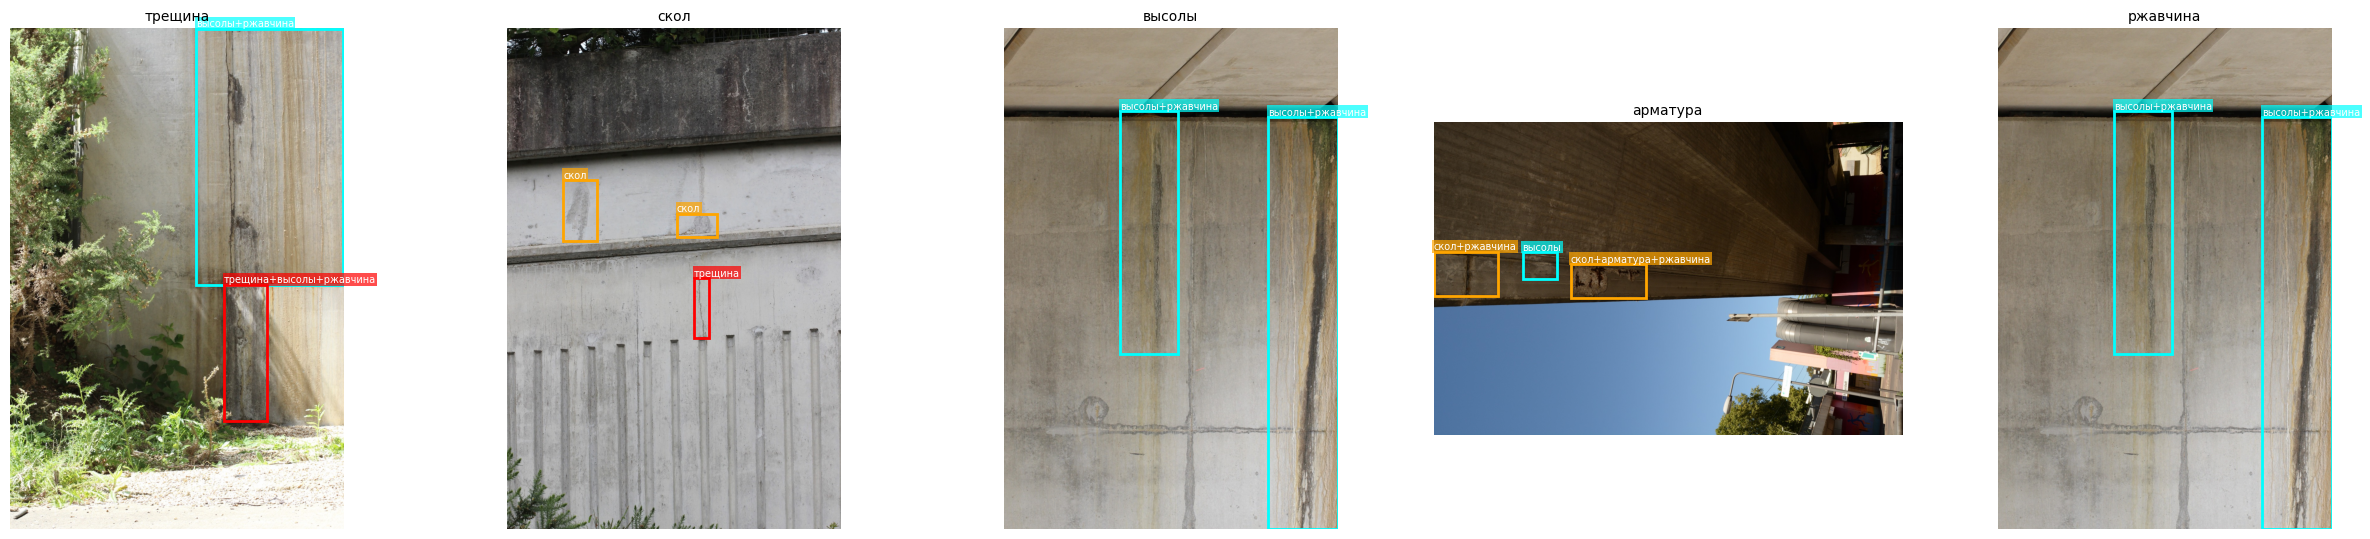

In [14]:
import matplotlib.patches as patches

COLORS = dict(crack='red', spallation='orange', efflorescence='cyan', exposed_bars='magenta', corrosion_stain='yellow')
SHORT = dict(crack='трещина', spallation='скол', efflorescence='высолы', exposed_bars='арматура', corrosion_stain='ржавчина')

def draw_example(ax, stem, title):
    img = Image.open(COMPACT_DIR / 'images' / f'{stem}.jpg')
    ax.imshow(img); ax.set_title(title, fontsize=10); ax.axis('off')
    for r in defect_boxes[defect_boxes['stem'] == stem].itertuples():
        labs = [c for c in DEFECTS if getattr(r, c)]
        ax.add_patch(patches.Rectangle((r.xmin, r.ymin), r.xmax - r.xmin, r.ymax - r.ymin,
                                       fill=False, edgecolor=COLORS[labs[0]], linewidth=2))
        ax.text(r.xmin, r.ymin - 8, '+'.join(SHORT[c] for c in labs), color='white', fontsize=7,
                bbox=dict(facecolor=COLORS[labs[0]], alpha=0.7, pad=1, edgecolor='none'))

fig, axes = plt.subplots(1, 5, figsize=(25, 5.5))
for ax, c in zip(axes, DEFECTS):
    stems = defect_boxes.loc[defect_boxes[c] == 1, 'stem']
    stems = [s for s in stems if split_of.get(s) == 'train'] or list(stems)
    draw_example(ax, stems[0], SHORT[c])
plt.tight_layout(); plt.savefig(FIG_DIR / 'dataset_examples.png', dpi=150); plt.show()

## Шаг 13. Обучаем базовую модель YOLOv8

- Загружаются веса YOLOv8, предобученные на COCO (**трансферное обучение**): модель уже умеет выделять края и текстуры, мы доучиваем её на повреждениях бетона.
- После каждой эпохи считаются метрики на val, лучшая модель сохраняется в `best.pt`.
- `patience=30`: если 30 эпох подряд нет улучшения, обучение останавливается (защита от переобучения).

Время на T4 при `IMG_SIZE=640`: YOLOv8n — около 50 минут на 100 эпох.

В логе: `box_loss, cls_loss, dfl_loss` должны уменьшаться, `P, R, mAP50, mAP50-95` — расти.

CODEBRIM — сложный набор: границы повреждений размыты, рамки перекрываются, классы несбалансированы, поэтому абсолютные значения метрик ниже, чем на «чистых» датасетах.

In [15]:
from ultralytics import YOLO

model = YOLO(MODEL_NAME)
model.train(
    data=str(data_yaml),
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH,
    seed=SEED,
    deterministic=True,
    patience=30,
    project=str(RUNS_DIR),
    name=RUN_NAME,
    exist_ok=True,
    plots=True,
)
RUN_DIR = Path(model.trainer.save_dir)
BEST_WEIGHTS = RUN_DIR / 'weights' / 'best.pt'
print('Обучение завершено. Лучшие веса:', BEST_WEIGHTS)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/codebrim_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, frac

## Шаг 14. Оценка на тестовой выборке

- **Precision** — доля найденных рамок, которые верны (меньше ложных срабатываний — выше precision).
- **Recall** — доля реальных повреждений, которые найдены.
- **F1** — гармоническое среднее precision и recall.
- **mAP@0.5** — средняя по классам точность при IoU ≥ 0,5; **mAP@0.5:0.95** — то же при строгих порогах IoU.
- **Время** — мс на одно фото.

Результат дописывается строкой в `results/summary.csv`; метрики по классам — в `results/per_class_<запуск>.csv`.

In [16]:
import datetime

best_model = YOLO(str(BEST_WEIGHTS))
m = best_model.val(data=str(data_yaml), split='test', imgsz=IMG_SIZE, batch=BATCH,
                   project=str(RUNS_DIR), name=RUN_NAME + '_test', exist_ok=True, plots=True)

P, R = float(m.box.mp), float(m.box.mr)
F1 = 2 * P * R / (P + R + 1e-9)
row = {
    'run': RUN_NAME, 'model': Path(MODEL_NAME).stem, 'imgsz': IMG_SIZE, 'seed': SEED, 'epochs': EPOCHS,
    'precision': round(P, 4), 'recall': round(R, 4), 'F1': round(F1, 4),
    'mAP50': round(float(m.box.map50), 4), 'mAP50_95': round(float(m.box.map), 4),
    'inference_ms': round(m.speed['inference'], 2), 'total_ms': round(sum(m.speed.values()), 2),
    'date': datetime.datetime.now().strftime('%Y-%m-%d %H:%M'),
}
summary_path = RES_DIR / 'summary.csv'
summary = pd.concat([pd.read_csv(summary_path), pd.DataFrame([row])]) if summary_path.exists() else pd.DataFrame([row])
summary = summary.drop_duplicates(subset='run', keep='last')
summary.to_csv(summary_path, index=False)

per_class = pd.DataFrame({
    'класс': [m.names[int(i)] for i in m.box.ap_class_index],
    'precision': np.round(m.box.p, 3), 'recall': np.round(m.box.r, 3),
    'AP50': np.round(m.box.ap50, 3), 'AP50_95': np.round(m.box.ap, 3),
})
per_class.to_csv(RES_DIR / f'per_class_{RUN_NAME}.csv', index=False, encoding='utf-8-sig')

print('=== Итог на TEST ===')
for k, v in row.items():
    print(f'{k:>14}: {v}')
display(per_class) if 'display' in globals() else print(per_class)

Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3411.7±812.3 MB/s, size: 444.1 KB)
val: Scanning /content/datasets/codebrim_yolo/labels/test... 239 images, 85 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 239/239 2.3Kit/s 0.1s
val: New cache created: /content/datasets/codebrim_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 2.9it/s 5.1s
                   all        239       1300       0.18      0.192      0.125     0.0454
                 crack        103        442      0.115      0.077     0.0432     0.0136
            spallation         89        291      0.253      0.344      0.207     0.0788
         efflorescence         48        126      0.067     0.0159     0.0209    0.00545
          exposed_bars         67        207      0.22

## Шаг 15. Графики обучения и ошибок

- `results.png` — потери и метрики по эпохам (если val loss растёт, а train падает — переобучение);
- `confusion_matrix_normalized.png` — какие классы путаются между собой и с фоном;
- `PR_curve.png` / `BoxPR_curve.png` — кривые precision–recall;
- `F1_curve.png` / `BoxF1_curve.png` — F1 в зависимости от порога уверенности (понадобится для каскада).

results.png


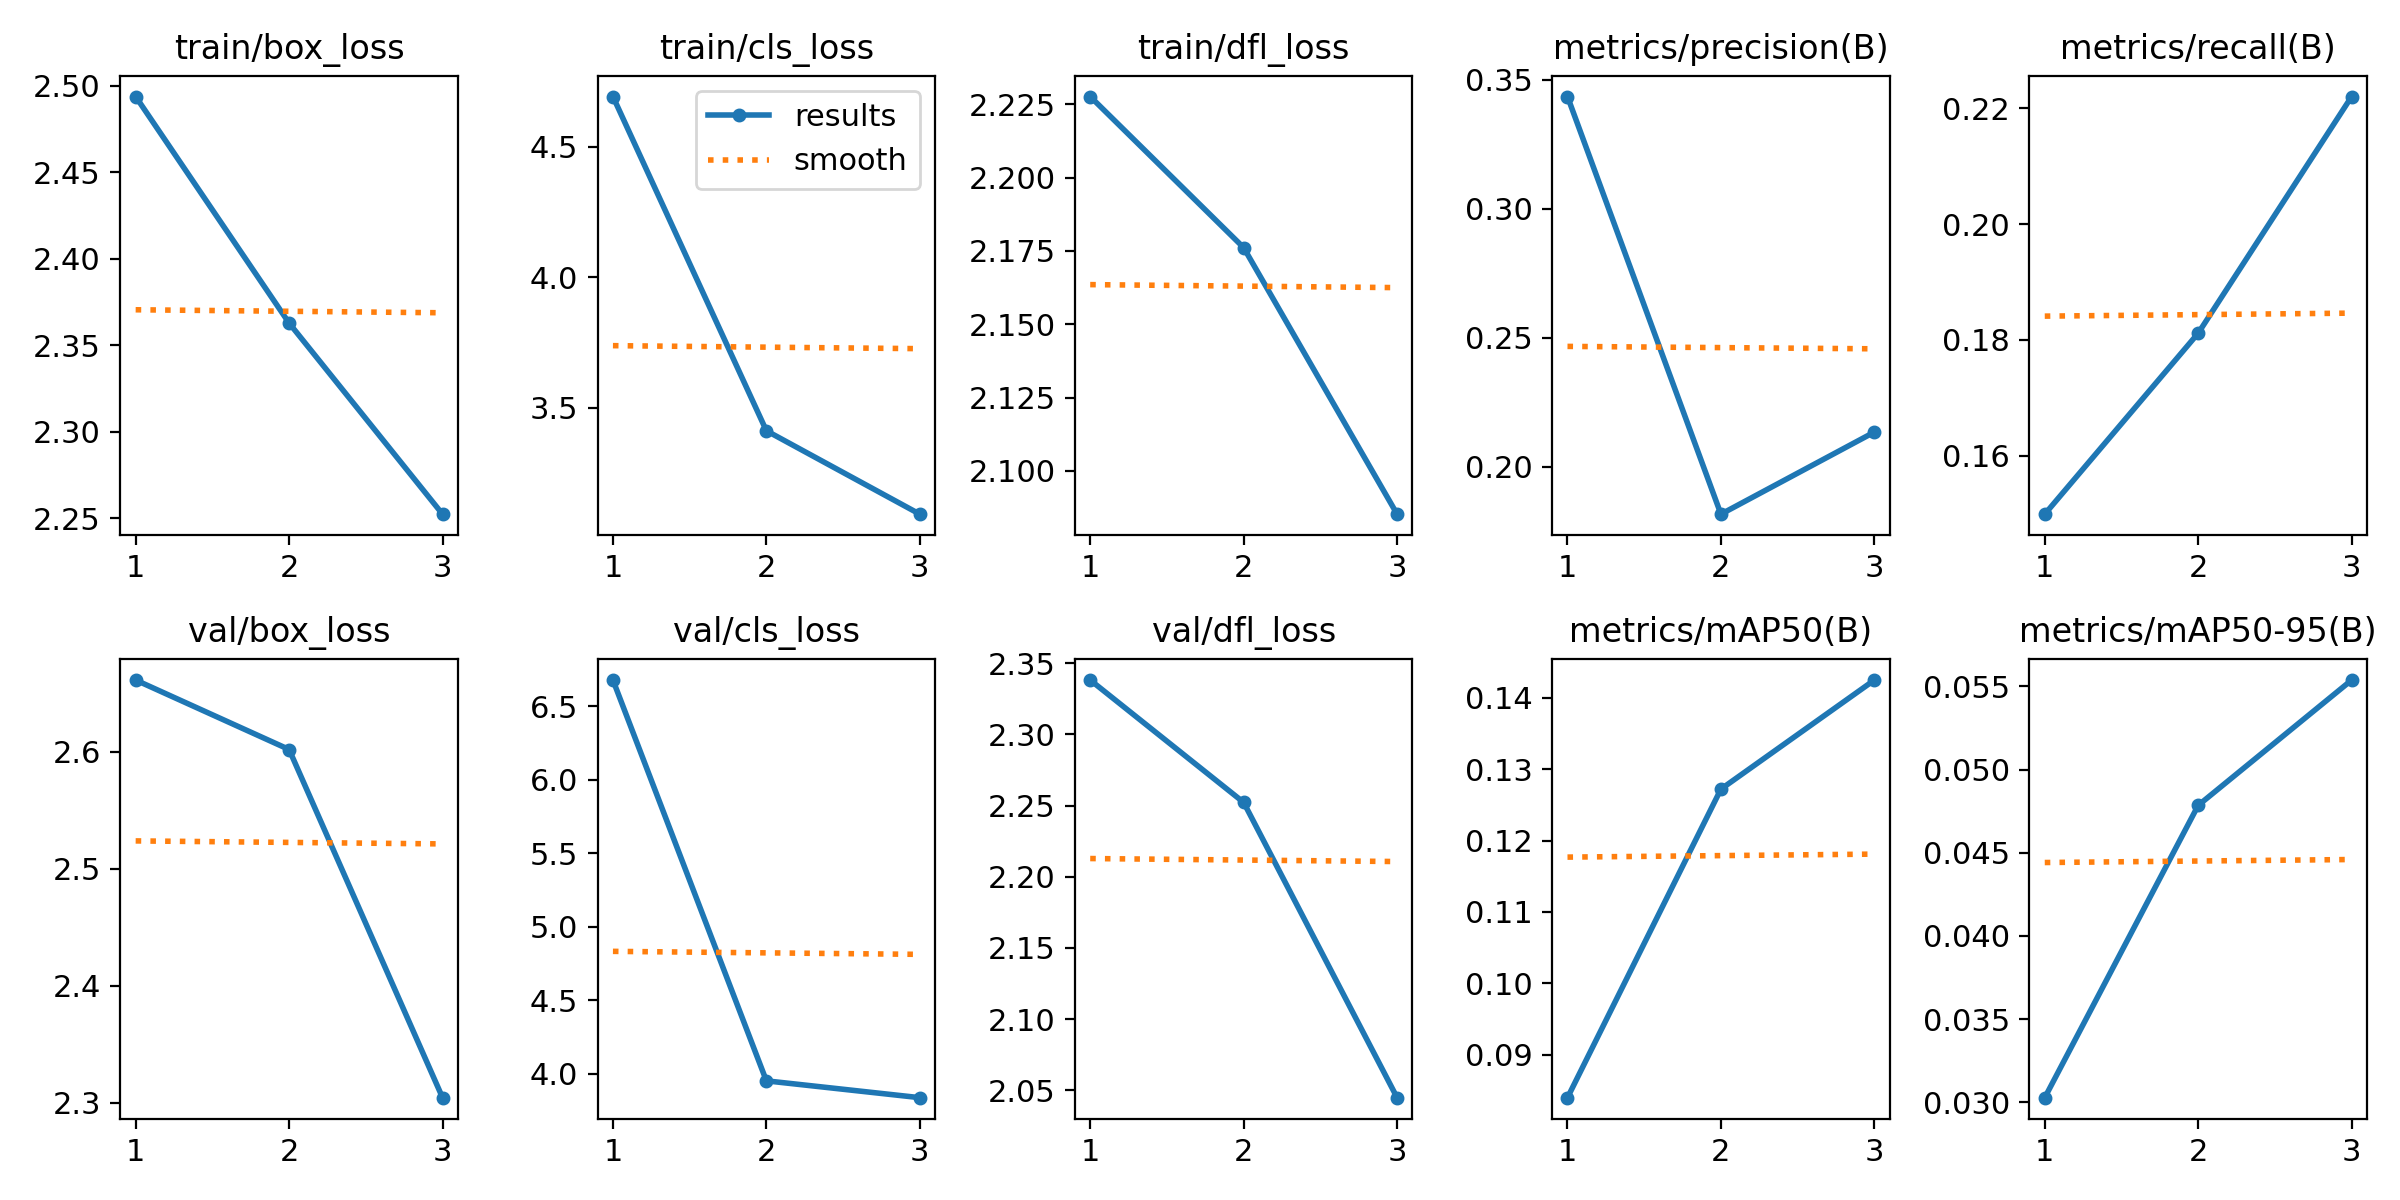

confusion_matrix_normalized.png


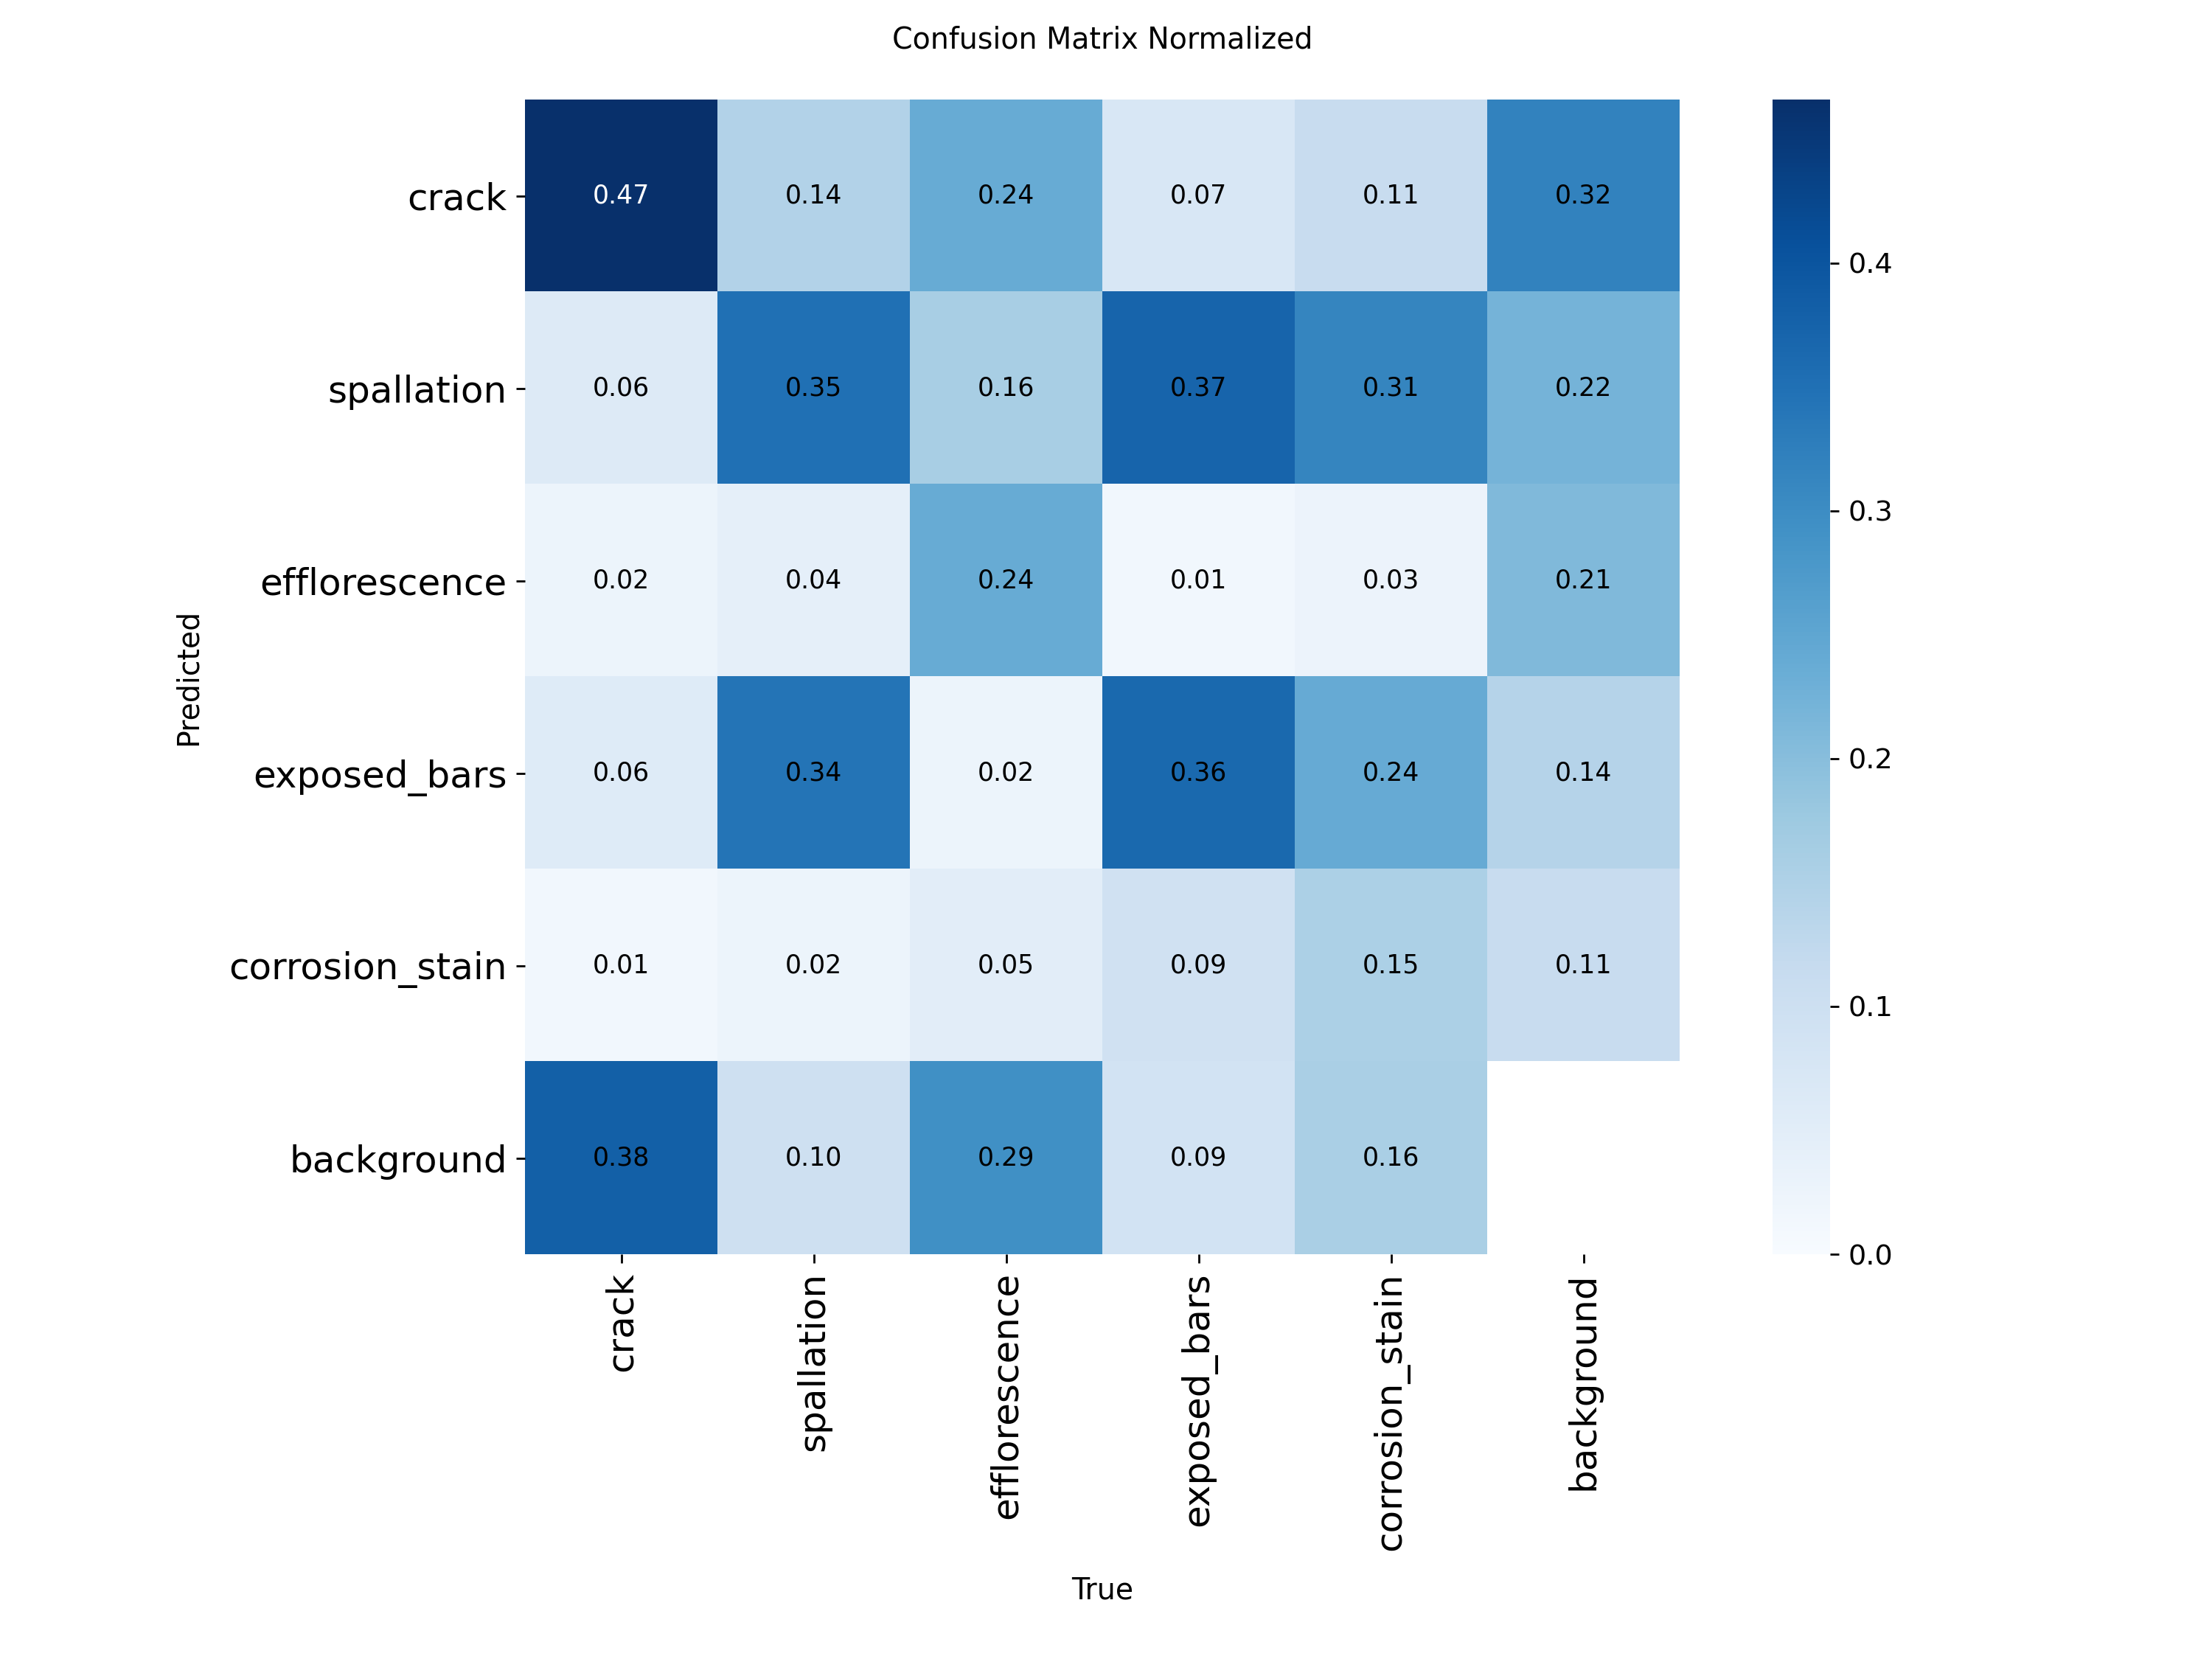

BoxPR_curve.png


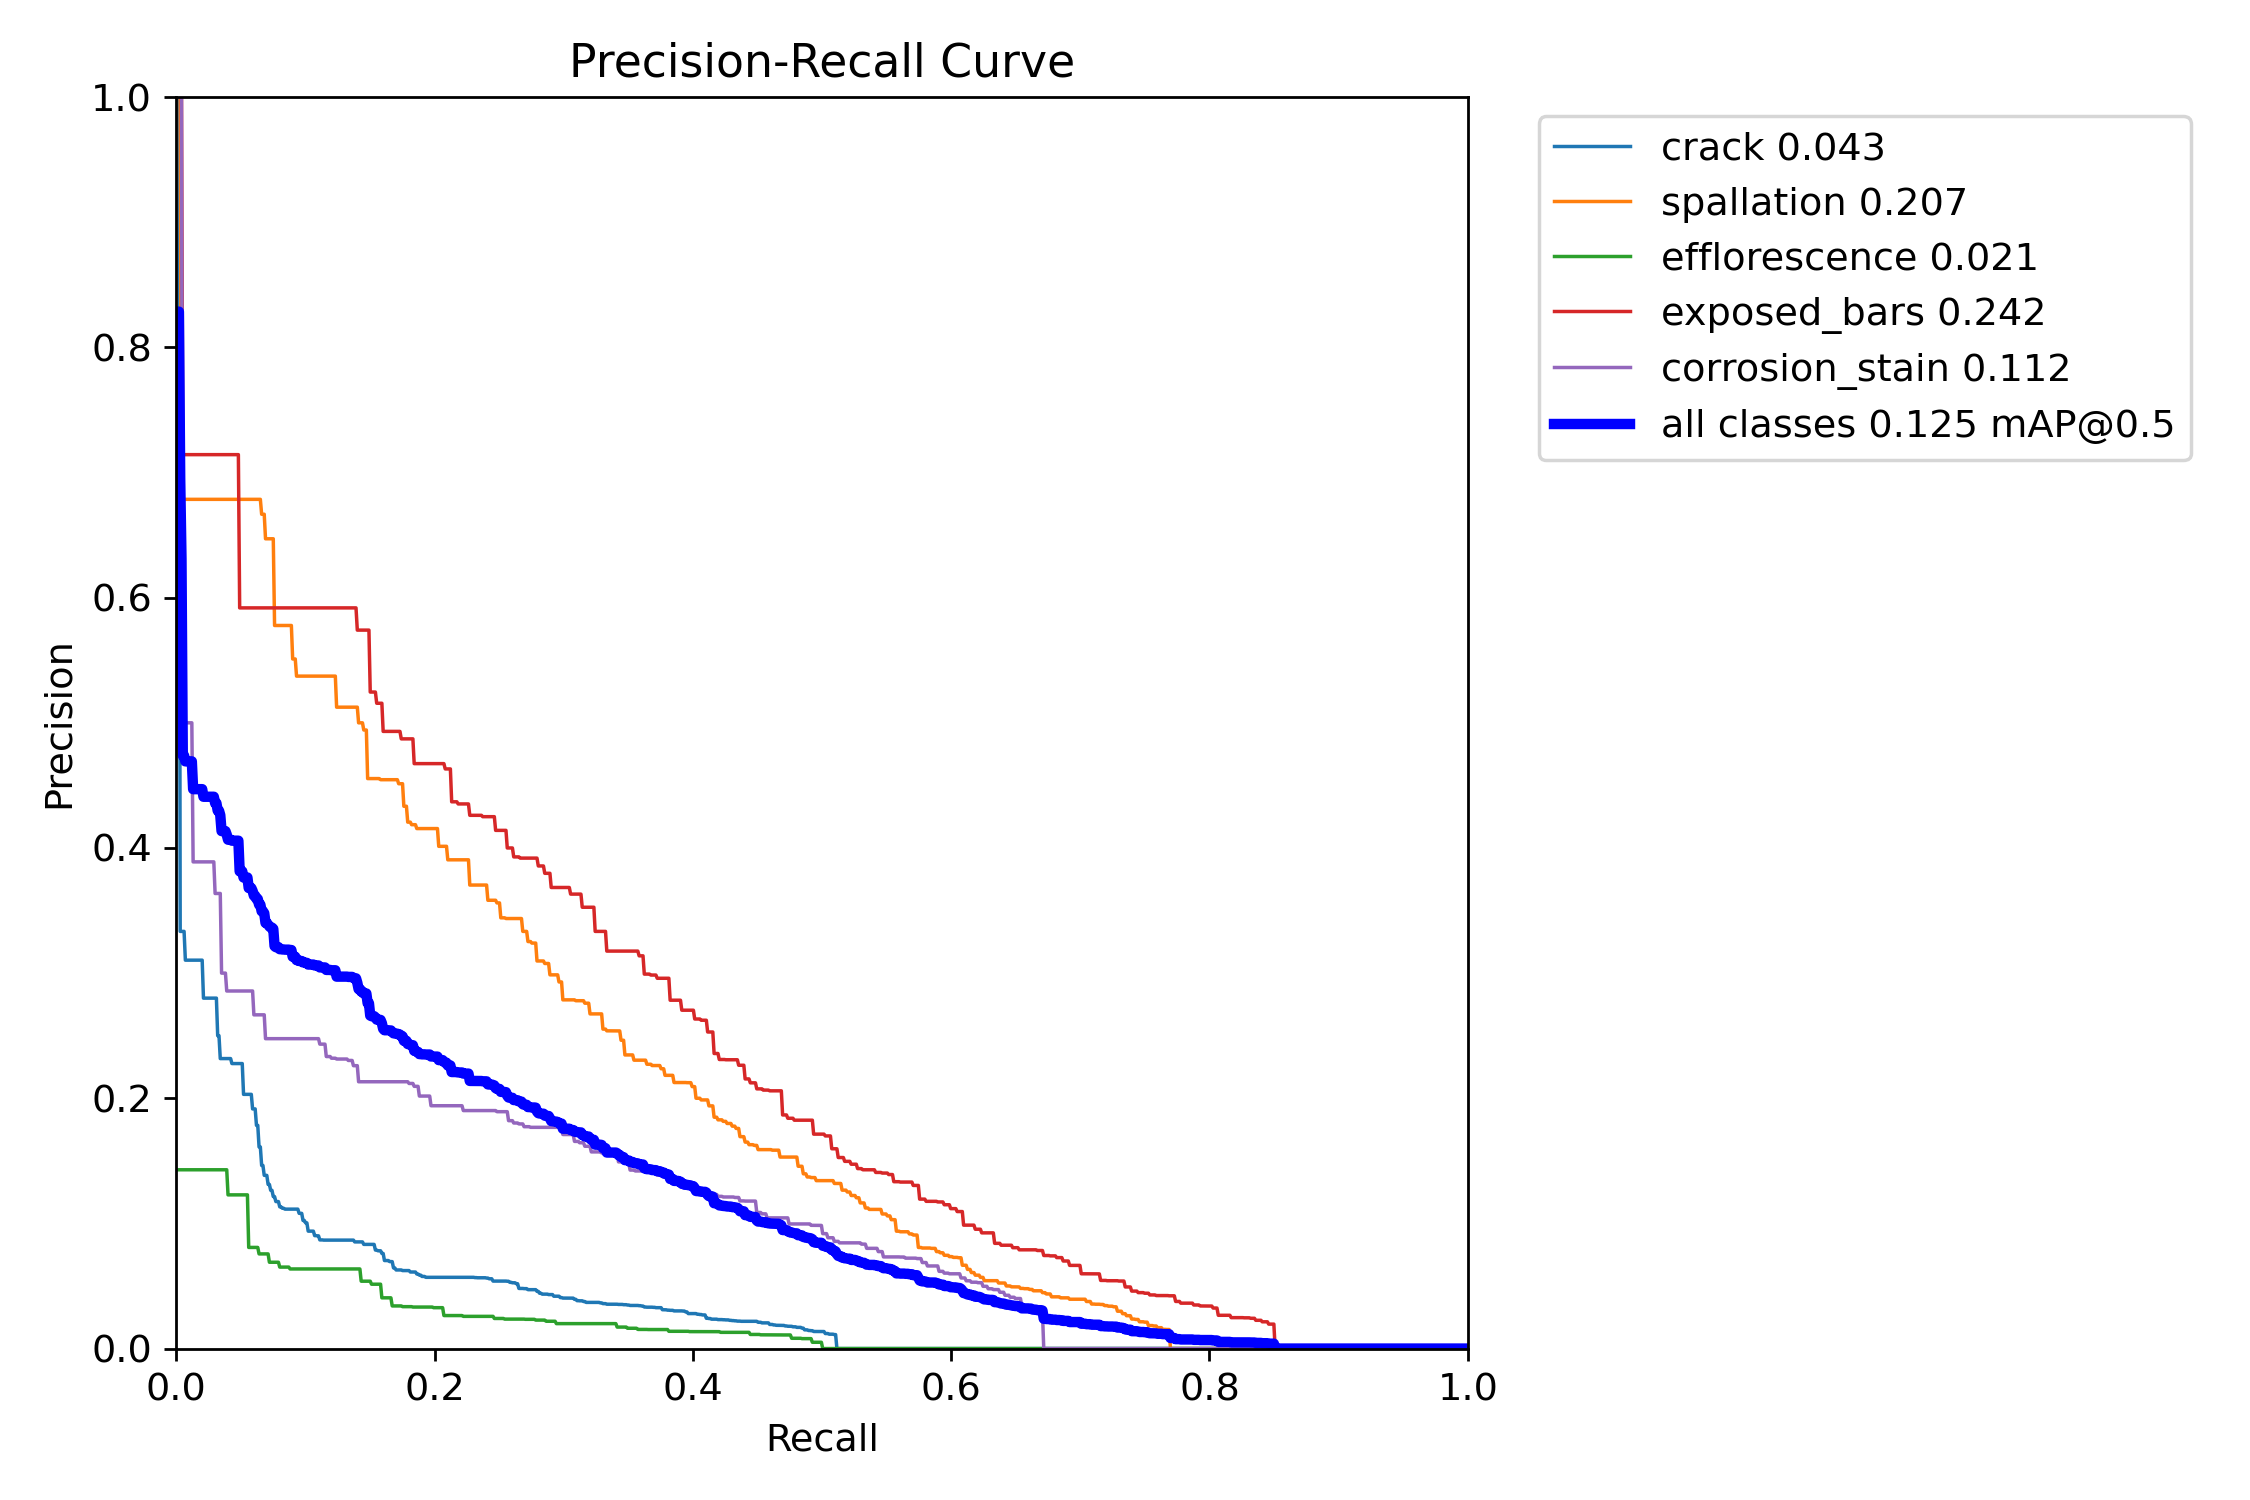

BoxF1_curve.png


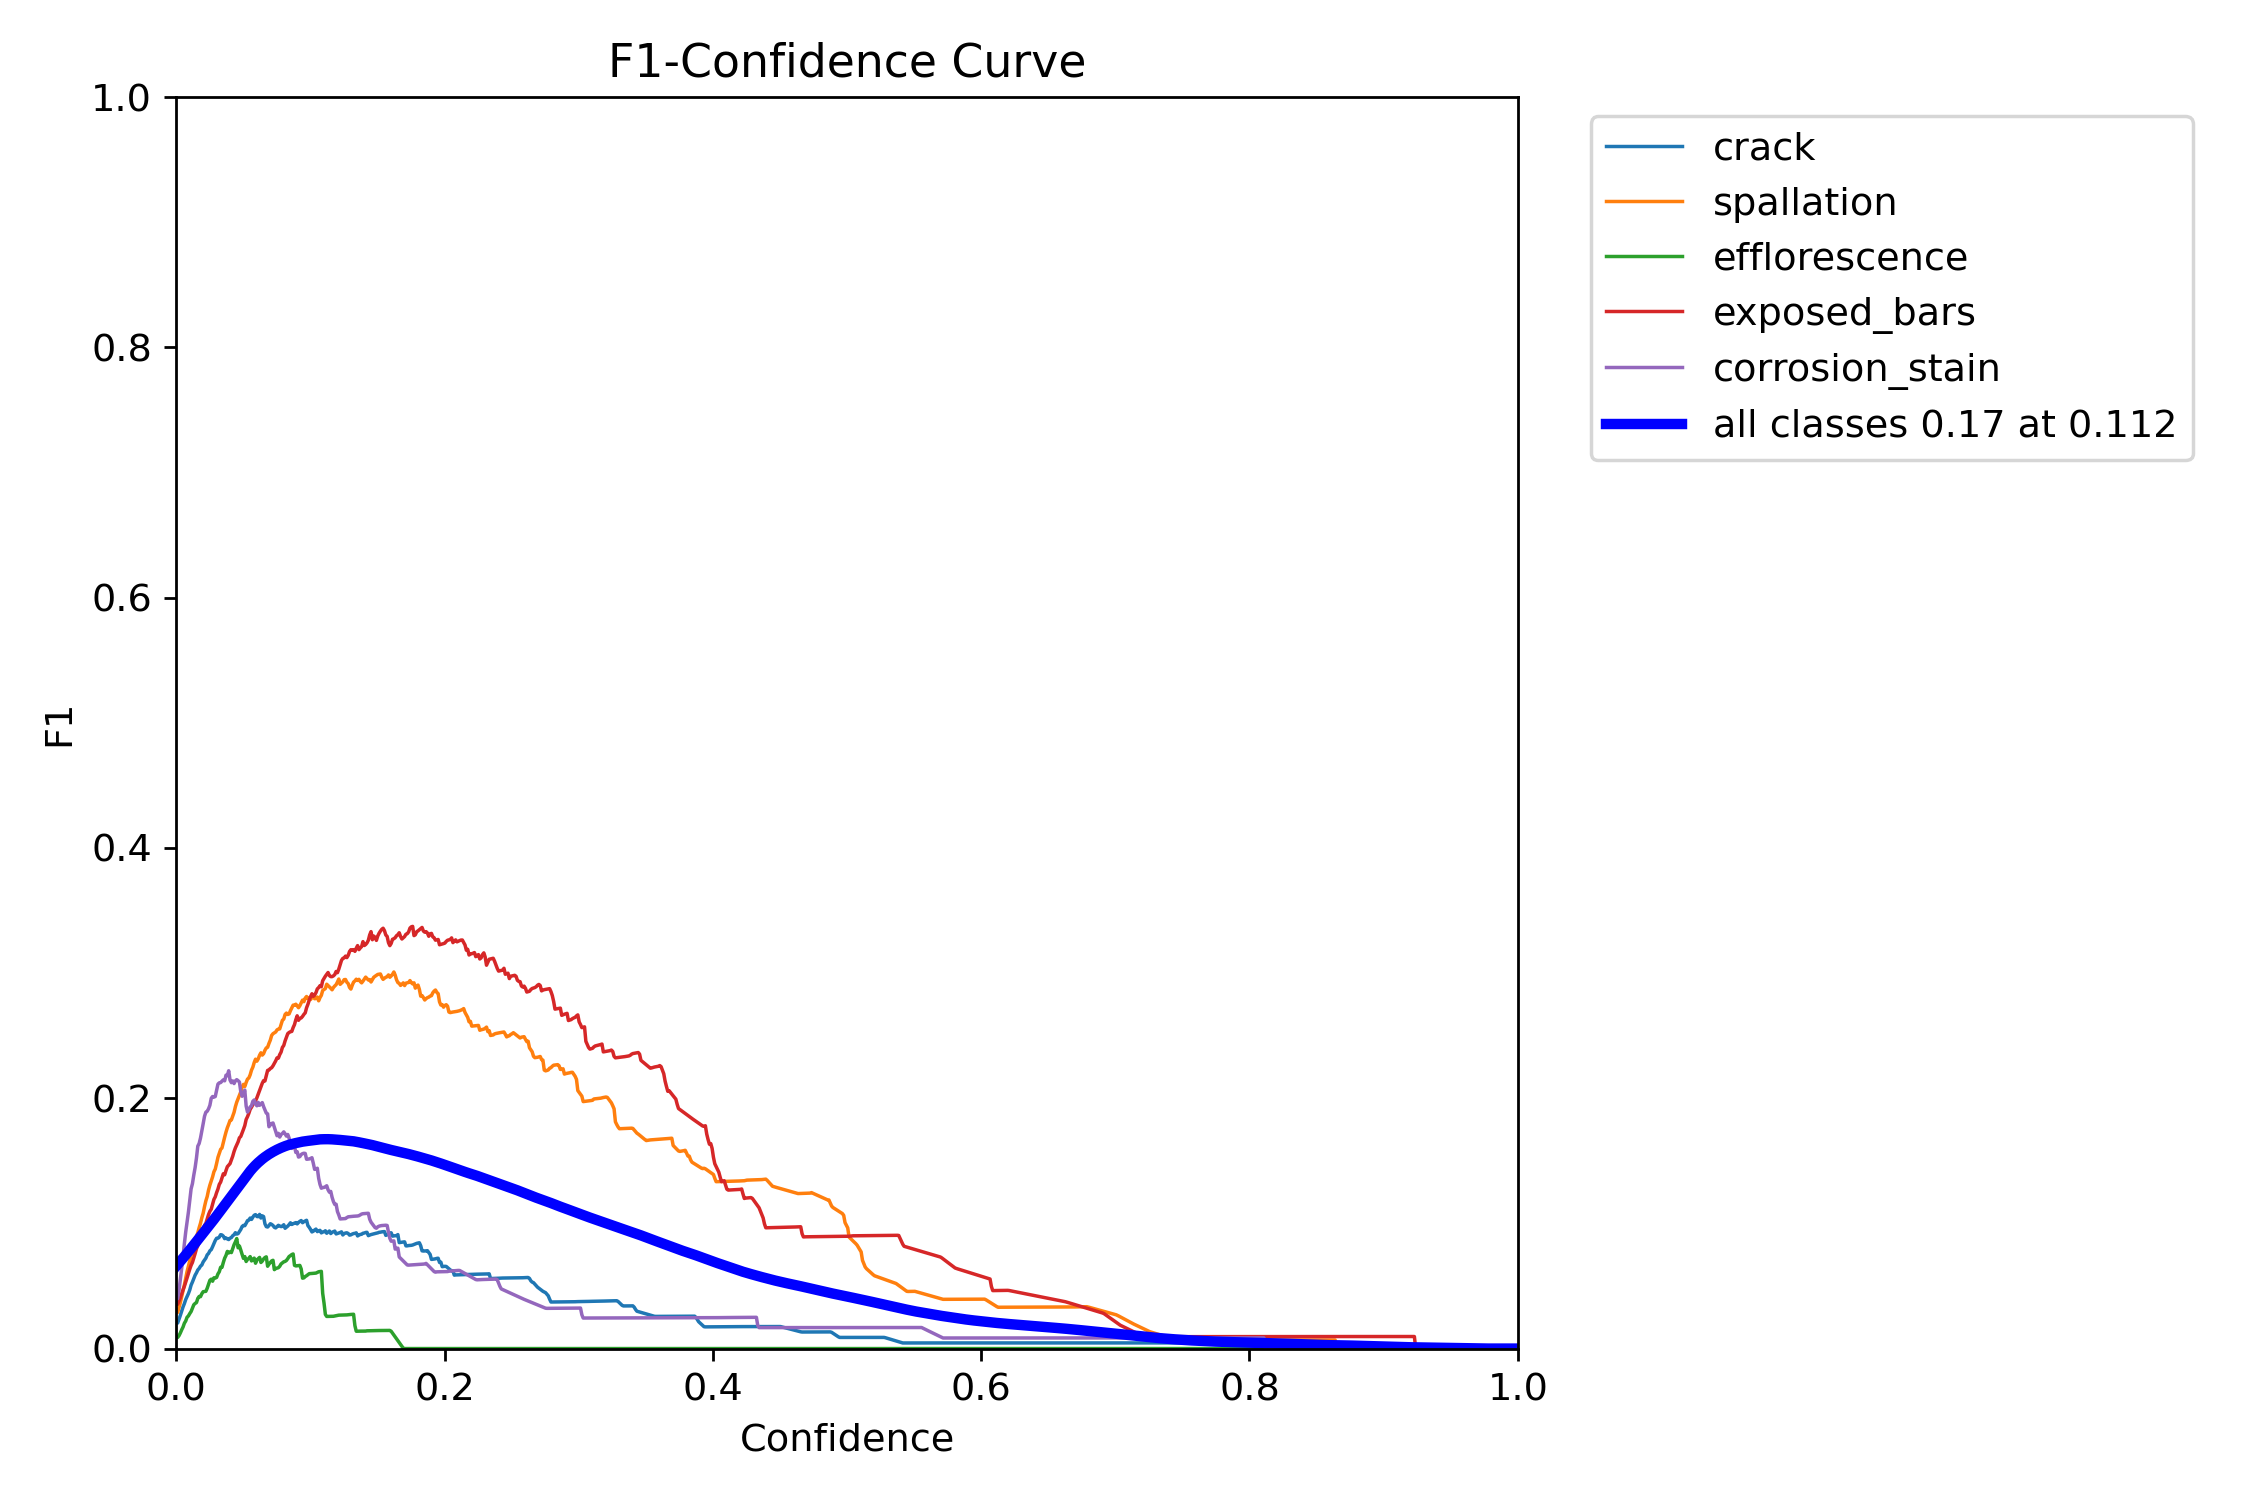

In [17]:
from IPython.display import Image as IPImage, display

TEST_DIR = RUNS_DIR / (RUN_NAME + '_test')
for path in [RUN_DIR / 'results.png', TEST_DIR / 'confusion_matrix_normalized.png',
             TEST_DIR / 'PR_curve.png', TEST_DIR / 'BoxPR_curve.png',
             TEST_DIR / 'F1_curve.png', TEST_DIR / 'BoxF1_curve.png']:
    if path.exists():
        print(path.name); display(IPImage(filename=str(path), width=800))

## Шаг 16. Предсказания модели на тестовых фото

По одному фото каждого класса и два фото без дефектов: видно пропуски, лишние рамки и путаницу классов.

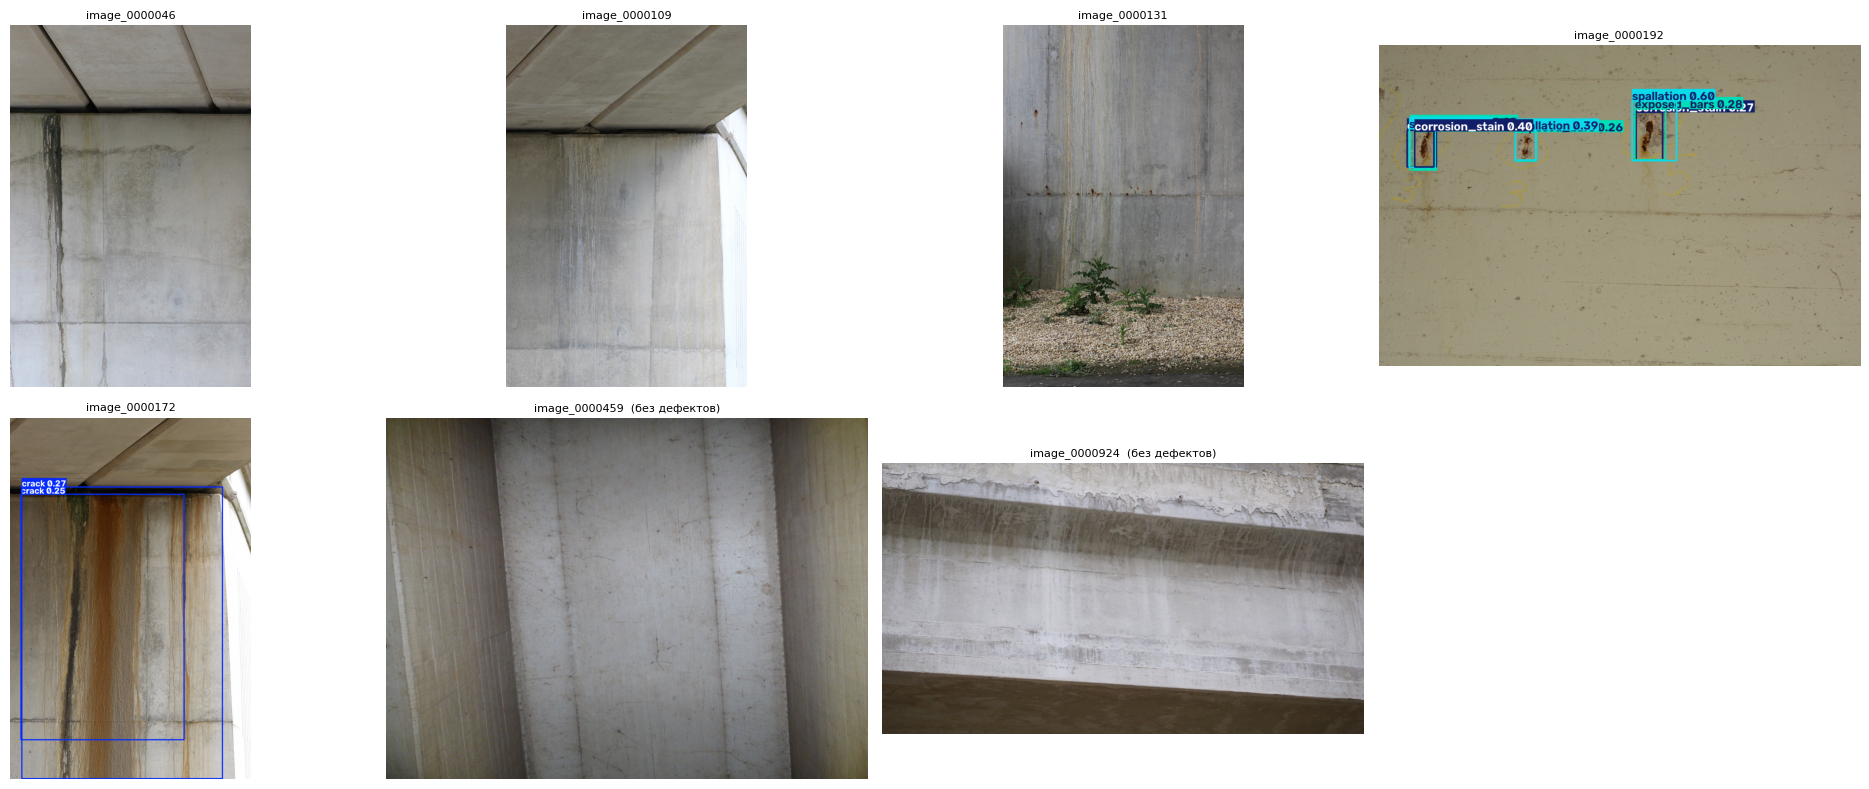

In [18]:
test_stems = [s for s, sp in split_of.items() if sp == 'test']
picked = []
for c in DEFECTS:
    cand = [s for s in defect_boxes.loc[defect_boxes[c] == 1, 'stem'].unique() if s in test_stems and s not in picked]
    picked += cand[:1]
picked += [s for s in test_stems if s not in imgs_with_defects][:2]

preds = best_model.predict([str(DATA_DIR / 'images' / 'test' / f'{s}.jpg') for s in picked],
                           imgsz=IMG_SIZE, conf=0.25, verbose=False)
cols = 4
rows_n = int(np.ceil(len(preds) / cols))
fig, axes = plt.subplots(rows_n, cols, figsize=(5 * cols, 4 * rows_n))
for ax, p, s in zip(np.atleast_1d(axes).flat, preds, picked):
    ax.imshow(p.plot()[:, :, ::-1]); ax.set_title(s + ('' if s in imgs_with_defects else '  (без дефектов)'), fontsize=8)
    ax.axis('off')
for ax in list(np.atleast_1d(axes).flat)[len(preds):]:
    ax.axis('off')
plt.tight_layout(); plt.savefig(FIG_DIR / f'predictions_{RUN_NAME}.png', dpi=130); plt.show()

## Шаг 17. Сводка по всем запускам (эпох по 100): среднее ± стандартное отклонение

Среднее и разброс по трём запускам (seed 0, 1, 2) одной модели.

In [19]:
if not (RES_DIR / 'summary.csv').exists():
    raise SystemExit('Пока нет результатов: сначала выполните шаги 13–14.')
summary = pd.read_csv(RES_DIR / 'summary.csv')
full = summary[~summary['run'].str.endswith('_quick')]
display(full) if 'display' in globals() else print(full)
if len(full):
    cols_m = ['precision', 'recall', 'F1', 'mAP50', 'mAP50_95', 'inference_ms']
    agg = full.groupby(['model', 'imgsz'])[cols_m].agg(['mean', 'std']).round(4)
    agg['n_runs'] = full.groupby(['model', 'imgsz']).size()
    agg.to_csv(RES_DIR / 'summary_mean_std.csv', encoding='utf-8-sig')
    display(agg) if 'display' in globals() else print(agg)

,run,model,imgsz,seed,epochs,precision,recall,F1,mAP50,mAP50_95,inference_ms,total_ms,date
1,yolov8n_img640_seed0,yolov8n,640,0,100,0.3992,0.3831,0.3910,0.3183,0.1529,3.87,9.74,2026-10-29 16:43
2,yolov8n_img640_seed1,yolov8n,640,1,100,0.4529,0.3780,0.4121,0.3392,0.1622,6.39,11.48,2026-10-29 19:04
3,yolov8n_img640_seed2,yolov8n,640,2,100,0.3855,0.4071,0.3960,0.3209,0.1504,4.15,9.40,2026-10-29 20:00
4,yolov8n_img640_seed0_quick2,yolov8n,640,0,3,0.1797,0.1922,0.1857,0.1252,0.0454,6.48,12.10,2026-10-30 14:03


precision        recall              F1           mAP50          \
                   mean   std    mean     std    mean     std    mean     std   
model   imgsz                                                                   
yolov8n 640      0.3543  0.12  0.3401  0.0994  0.3462  0.1074  0.2759  0.1009   

              mAP50_95         inference_ms         n_runs  
                  mean     std         mean     std         
model   imgsz                                               
yolov8n 640     0.1277  0.0551       5.2225  1.4052      4

## Продолжение прерванного обучения

1. Запустить шаги 1–4 и 9–12
2. Вместо шага 13 запустить ячейку ниже — обучение продолжится с последней эпохи.
3. Затем шаги 14–17.

In [ ]:
# ПРОДОЛЖЕНИЕ ПРЕРВАННОГО ОБУЧЕНИЯ:
# from ultralytics import YOLO
# model = YOLO(str(RUNS_DIR / RUN_NAME / 'weights' / 'last.pt'))
# model.train(resume=True)
# RUN_DIR = Path(model.trainer.save_dir)
# BEST_WEIGHTS = RUN_DIR / 'weights' / 'best.pt'

## Результаты

YOLOv8n, 640 px, test (239 фото), три запуска:

| Запуск | Precision | Recall | F1 | mAP@0.5 | mAP@0.5:0.95 |
|---|---|---|---|---|---|
| seed 0 | 0.399 | 0.383 | 0.391 | 0.318 | 0.153 |
| seed 1 | 0.453 | 0.378 | 0.412 | 0.339 | 0.162 |
| seed 2 | 0.386 | 0.407 | 0.396 | 0.321 | 0.150 |
| **Среднее ± std** | **0.413 ± 0.036** | **0.389 ± 0.016** | **0.400 ± 0.011** | **0.326 ± 0.011** | **0.155 ± 0.006** |

**Выводы:**
- Результат воспроизводим: коэффициент вариации mAP@0.5 — 3.5 %.
- Лучше всего находится оголённая арматура (AP@0.5 = 0.49), хуже всего — высолы (0.22) и трещины (0.18): тонкие объекты и самый редкий класс.
- 65 % ложных срабатываний — «трещины» на швах опалубки, стыках и тенях.
- Оптимальный порог уверенности различается по классам (0.22 для трещин, 0.33 для арматуры) — единый порог неоптимален.

## Дальше

- YOLOv8s и сравнение размера входа 640 / 1024 (тонкие трещины).
- **Этап 2:** классификатор фрагментов как второй каскад — отсеивает ложные срабатывания детектора; подбор порогов каскада по классам.
